In [1]:
import awkward as ak
import uproot
from coffea.nanoevents import NanoEventsFactory, NanoAODSchema
from coffea.nanoevents.methods import vector
import numpy as np
from coffea import util

In [2]:
import coffea
coffea.__version__

'0.7.12'

In [49]:
fileset = {
    "WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____4_": 
    [
            "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/8A16FAF9-40C4-9042-A888-CC6FF79132BD.root",

            "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL16NanoAODAPVv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_preVFP_v11-v1/120000/9415D956-D0B9-8A41-983B-FE788C588854.root",
#                     "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/D62C3915-5A89-0245-B798-CA424003CE1E.root"

            "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/TTToSemiLeptonic_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/280000/EB3DEDC6-3E18-F041-B257-FE052E8B1ECD.root",
        
    "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL17NanoAODv9/WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_mc2017_realistic_v9-v1/280000/373E49F8-8178-0B40-87C2-797A66071077.root",

            "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL16NanoAODv9/WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/130000/92A8C1A6-2737-A748-87A0-CBBC04ED2BEB.root"
        ],

#     "EG":
#     [
#             "root://cmsxrootd.fnal.gov//store/data/Run2018D/EGamma/NANOAOD/UL2018_MiniAODv2_NanoAODv9-v3/250000/EFD7FC16-DDD3-654A-884D-9A175D7467A2.root"
#         ],
}
fname = fileset["WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____4_"][0]
events = NanoEventsFactory.from_root(fname, schemaclass=NanoAODSchema).events()

In [4]:
events.PV.fields

['ndof', 'x', 'y', 'z', 'chi2', 'score', 'npvs', 'npvsGood']

In [40]:
import correctionlib
def GetPUSF(IOV, nTrueInt, var='nominal'):
    fname = "../../data/pileup/UL/puWeights"+IOV+".json.gz"
    hname = {
        "2016preVFP": "Collisions16_UltraLegacy_goldenJSON",
        "2016postVFP"   : "Collisions16_UltraLegacy_goldenJSON",
        "2017"   : "Collisions17_UltraLegacy_goldenJSON",
        "2018"   : "Collisions18_UltraLegacy_goldenJSON"
    }
    evaluator = correctionlib.CorrectionSet.from_file(fname)
    return evaluator[hname[IOV]].evaluate(np.array(nTrueInt), var)


In [63]:
nom = GetPUSF('2018',(np.linspace(0,100,101)))
up    = GetPUSF('2018', (np.linspace(0,100,101)), "up")
down    = GetPUSF('2018', (np.linspace(0,100,101)), "down")


In [52]:
arr = np.linspace(0,100,101)

In [53]:
arr

array([  0.,   1.,   2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.,  10.,
        11.,  12.,  13.,  14.,  15.,  16.,  17.,  18.,  19.,  20.,  21.,
        22.,  23.,  24.,  25.,  26.,  27.,  28.,  29.,  30.,  31.,  32.,
        33.,  34.,  35.,  36.,  37.,  38.,  39.,  40.,  41.,  42.,  43.,
        44.,  45.,  46.,  47.,  48.,  49.,  50.,  51.,  52.,  53.,  54.,
        55.,  56.,  57.,  58.,  59.,  60.,  61.,  62.,  63.,  64.,  65.,
        66.,  67.,  68.,  69.,  70.,  71.,  72.,  73.,  74.,  75.,  76.,
        77.,  78.,  79.,  80.,  81.,  82.,  83.,  84.,  85.,  86.,  87.,
        88.,  89.,  90.,  91.,  92.,  93.,  94.,  95.,  96.,  97.,  98.,
        99., 100.])

In [9]:
year = "2016"

corrections = util.load('../../data/corrections.coffea')
get_pu_nom_weight = corrections['get_pu_nom_weight_postVFP'][year]
get_pu_up_weight = corrections['get_pu_up_weight_postVFP'][year]
get_pu_down_weight = corrections['get_pu_down_weight_postVFP'][year]
# arr = events.Pileup.nPU
nom=np.minimum(5,get_pu_nom_weight(arr))
up=np.minimum(5, get_pu_up_weight(arr))
down=np.minimum(5,get_pu_down_weight(arr))

In [10]:
(nom), (up),(down)

(<Array [1.41, 0.859, 0.792, ... 1.72, 2.41] type='133026 * float64'>,
 <Array [1.46, 0.79, 0.71, ... 0.887, 5, 5] type='133026 * float64'>,
 <Array [1.3, 0.935, 0.874, ... 0.294, 0.755] type='133026 * float64'>)

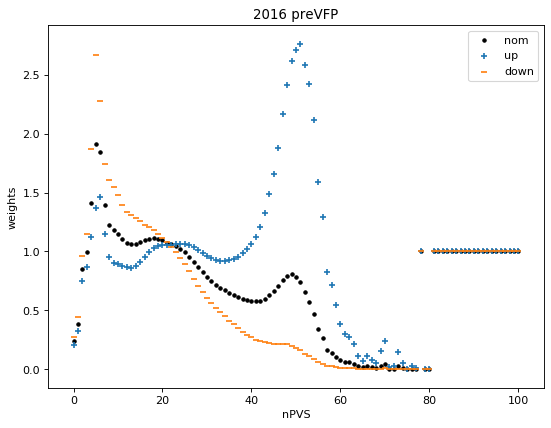

In [58]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
# arr = events.Pileup.nTrueInt
figure(figsize=(8, 6), dpi=80)
plt.scatter(arr, nom, marker='.', label="nom", color='black')
plt.scatter(arr, up, marker="+", label="up")
plt.scatter(arr, down, marker='_', label='down')
plt.legend()
plt.xlabel("nPVS")
plt.ylabel("weights")
plt.title("2016 preVFP")
plt.show()

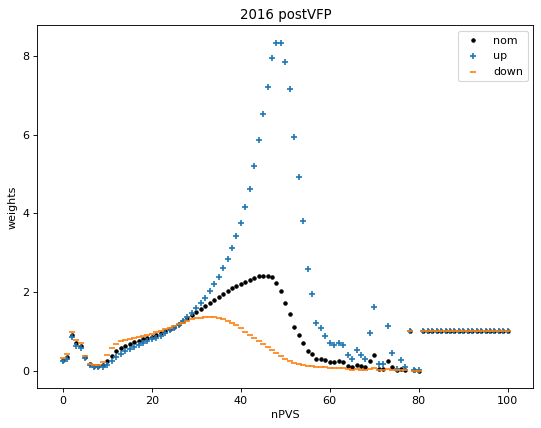

In [60]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

figure(figsize=(8, 6), dpi=80)
plt.scatter(arr, nom, marker='.', label="nom", color='black')
plt.scatter(arr, up, marker="+", label="up")
plt.scatter(arr, down, marker='_', label='down')
plt.legend()
plt.xlabel("nPVS")
plt.ylabel("weights")
plt.title("2016 postVFP")
plt.show()

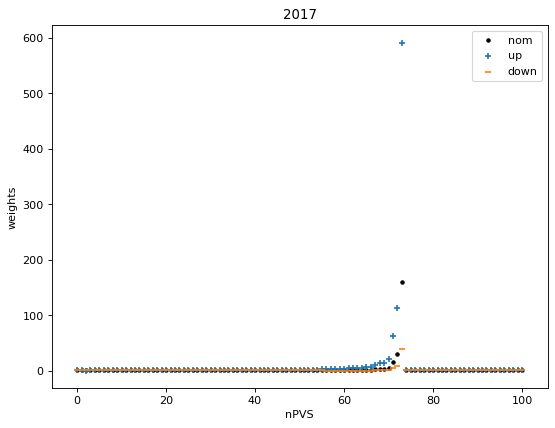

In [62]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

figure(figsize=(8, 6), dpi=80)
plt.scatter(arr, nom, marker='.', label="nom", color='black')
plt.scatter(arr, up, marker="+", label="up")
plt.scatter(arr, down, marker='_', label='down')
plt.legend()
plt.xlabel("nPVS")
plt.ylabel("weights")
plt.title("2017")
plt.show()

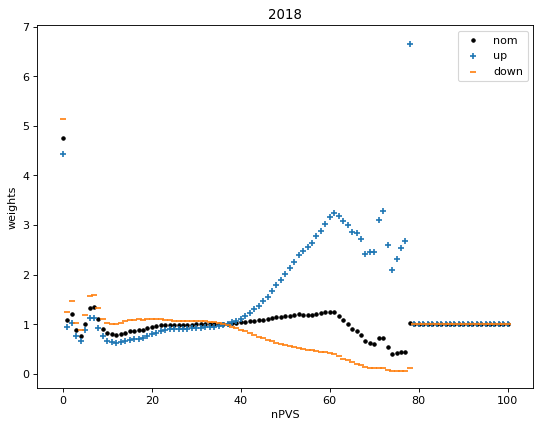

In [64]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
figure(figsize=(8, 6), dpi=80)
plt.scatter(arr, nom, marker='.', label="nom", color='black')
plt.scatter(arr, up, marker="+", label="up")
plt.scatter(arr, down, marker='_', label='down')
plt.legend()
plt.xlabel("nPVS")
plt.ylabel("weights")
plt.title("2018")
plt.show()

In [4]:
from coffea import util
corrections = util.load("../../data/corrections.coffea")
get_ele_trig_weight = corrections['get_ele_trig_weight']['2018']

In [5]:
corrections = util.load("../../data/corrections.coffea")
get_deepflav_weight = corrections['get_btag_weight_postVFP']['deepflav']['2018']

common = util.load('../../data/common.coffea')
deepflavWPs = common['btagWPs']['deepflav']['2018']

_ids = util.load("../../data/ids.coffea")
isLooseElectron = _ids['isLooseElectron']
isTightElectron = _ids['isTightElectron']
isLooseMuon = _ids['isLooseMuon']
isTightMuon = _ids['isTightMuon']
isLooseTau = _ids['isLooseTau']
isLoosePhoton = _ids['isLoosePhoton']
isTightPhoton = _ids['isTightPhoton']
isGoodJet = _ids['isGoodJet']
isHEMJet = _ids['isHEMJet']
get_deepflav_weight = corrections['get_btag_weight_postVFP']['deepflav']['2018']

In [6]:
year = '2018'
met = events.MET
met["T"] = ak.zip({"pt": met.pt, "phi": met.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)

calomet = events.CaloMET
puppimet = events.PuppiMET
puppimet["T"] = ak.zip({"pt": puppimet.pt, "phi": puppimet.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)

###
# Initialize physics objects
###

mu = events.Muon
mu['isloose'] = isLooseMuon(mu.pt, mu.eta, mu.pfIsoId, mu.looseId, year, mu.isPFcand,
                           mu.isGlobal,
                           mu.isTracker)
mu['istight'] = isTightMuon(mu.pt, mu.eta, mu.pfIsoId, mu.tightId, year, mu.isPFcand,
                                   mu.isGlobal,
                                   mu.isTracker)
mu["T"] = ak.zip({"pt": mu.pt, "phi": mu.phi}, 
          with_name="PolarTwoVector", 
          behavior=vector.behavior)
mu['p4'] = ak.zip({
                    "pt": mu.pt,
                    "eta": mu.eta,
                    "phi": mu.phi,
                    "mass": mu.mass},
                    with_name="PtEtaPhiMLorentzVector",
)


mu_loose = mu[ak.values_astype(mu.isloose, np.bool)]
mu_tight = mu[ak.values_astype(mu.istight, np.bool)]
ak.num(mu, axis=1)
mu_ntot = ak.num(mu, axis=1)
mu_nloose = ak.num(mu_loose, axis=1)
mu_ntight = ak.num(mu_tight, axis=1)
leading_mu = mu_tight[:,:1]


e = events.Electron
event_size = len(e)


e['isclean'] = ak.all(e.metric_table(mu_loose) > 0.3, axis=-1)
e['isloose'] = isLooseElectron(e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, year)
e['istight'] = isTightElectron(e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, year)
#         e['T'] = TVector2Array.from_polar(e.pt, e.phi)
e["T"] = ak.zip({"pt": e.pt, "phi": e.phi}, 
          with_name="PolarTwoVector", 
          behavior=vector.behavior)
e['p4'] = ak.zip({
                    "pt": e.pt,
                    "eta": e.eta,
                    "phi": e.phi,
                    "mass": e.mass},
                    with_name="PtEtaPhiMLorentzVector",
)
e_clean = e[ak.values_astype(e.isclean, np.bool)]
e_loose = e_clean[ak.values_astype(e_clean.isloose, np.bool)]
e_tight = e_clean[ak.values_astype(e_clean.istight, np.bool)]
e_ntot = ak.num(e, axis=1)
e_nloose = ak.num(e_loose, axis=1)

#         e_nloose = e_loose.counts
e_ntight = ak.num(e_tight, axis=1)
leading_e = e_tight[:,:1]


tau = events.Tau
tau['isclean'] = ak.all(tau.metric_table(mu_loose) > 0.4, axis=-1) & ak.all(tau.metric_table(e_loose) > 0.4, axis=-1)
#         ak.all(tau.metric_table(mu_loose) > 0.4, axis=-1)
try:
    tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayMode,tau.idDeepTau2017v2p1VSjet,year)
except:
    tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeOldDMs,tau.idDeepTau2017v2p1VSjet,year)
else: 
    tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeNewDMs,tau.idDeepTau2017v2p1VSjet,year)

tau_clean = tau[ak.values_astype(tau.isclean, np.bool)]

tau_loose = tau_clean[ak.values_astype(tau_clean.isloose, np.bool)]
tau_ntot = ak.num(tau, axis=1)
tau_nloose = ak.num(tau_loose, axis=1)

pho = events.Photon
pho['isclean'] = ak.all(pho.metric_table(mu_loose) > 0.4, axis=-1) & ak.all(pho.metric_table(e_loose) > 0.4, axis=-1)
_id = 'cutBased'
if year == '2016':
    _id = 'cutBased'
pho['isloose'] = isLoosePhoton(pho.pt, pho.eta, pho[_id], year) & (pho.electronVeto)  # added electron veto flag
pho['istight'] = isTightPhoton(pho.pt, pho[_id], year) & (pho.isScEtaEB) & (pho.electronVeto)  # tight photons are barrel only

pho["T"] = ak.zip({"pt": pho.pt, "phi": pho.phi}, 
          with_name="PolarTwoVector", 
          behavior=vector.behavior)

pho_clean = pho[ak.values_astype(pho.isclean, np.bool)]
pho_loose = pho_clean[ak.values_astype(pho_clean.isloose, np.bool)]
pho_tight = pho_clean[ak.values_astype(pho_clean.istight, np.bool)]
pho_ntot = ak.num(pho,axis=1)
pho_nloose = ak.num(pho_loose, axis=1)
pho_ntight = ak.num(pho_tight, axis=1)
leading_pho = pho[:,:1] #new way to define leading photon
leading_pho = leading_pho[ak.values_astype(leading_pho.isclean, np.bool)]

leading_pho = leading_pho[ak.values_astype(leading_pho.istight, np.bool)]
leading_pho = leading_pho[ak.values_astype(leading_pho.istight, np.bool)]

j = events.Jet
NumNeutralParticles = (j.nConstituents-j.nElectrons-j.nMuons)
NumConst = j.nConstituents
NHF = j.neHEF
NEMF = j.neEmEF
CHF = j.chHEF
MUF = j.muEF
CEMF = j.chEmEF
CHM = j.nElectrons+j.nMuons
#1 Select good jets
 
j['isgood'] = isGoodJet(j.pt, j.eta, j.jetId, j.puId,NHF, NEMF, NumConst, MUF, CHF, CHM, CEMF, year)
j['isHEM'] = isHEMJet(j.pt, j.eta, j.phi)

# j['isdflvL'] = (j.btagDeepFlavB>deepflavWPs['loose'])
j['isdflvM'] = (j.btagDeepFlavB > deepflavWPs['medium']) ## from Rishab
# j['isdcsvM'] = (j.btagDeepB > deepcsvWPs['medium']) ## from Rishabh

j["T"] = ak.zip({"pt": j.pt, "phi": j.phi}, 
          with_name="PolarTwoVector", 
          behavior=vector.behavior)
j['p4'] = ak.zip({
"pt": j.pt,
"eta": j.eta,
"phi": j.phi,
"mass": j.mass},
with_name="PtEtaPhiMLorentzVector",
)

#         https://coffeateam.github.io/coffea/modules/coffea.nanoevents.methods.vector.html#
#         j['ptRaw'] =j.pt * (1-j.rawFactor)
#         j['massRaw'] = j.mass * (1-j.rawFactor)
#         j['rho'] = j.pt.ones_like()*events.fixedGridRhoFastjetAll.array

#         j_dflvL = j_clean[j_clean.isdflvL.astype(np.bool)]
jetMuMask = ak.all(j.metric_table(mu_loose) > 0.4, axis=-1)
jetEleMask = ak.all(j.metric_table(e_loose) > 0.4, axis=-1)
jetPhoMask = ak.all(j.metric_table(pho_loose) > 0.4, axis=-1)

j_isclean_mask = (jetMuMask & jetEleMask & jetPhoMask)
j_isgood_mask = isGoodJet(j.pt, j.eta, j.jetId, j.puId,NHF, NEMF, NumConst, MUF, CHF, CHM, CEMF, year)
j_good_clean = j[j_isclean_mask & j_isgood_mask]
j_ngood_clean = ak.num(j_good_clean)
# j_good_clean_dflvB = j_good_clean.isdflvM
# j_ndflvM = ak.num(j[j_good_clean_dflvB])
leading_j = j_good_clean[:,:1] # new way to define leading jet
j_HEM = j[ak.values_astype(j.isHEM, np.bool)]       
j_nHEM = ak.num(j_HEM, axis=1)

In [7]:
import os.path
from coffea import util
from coffea.btag_tools import BTagScaleFactor
from coffea.jetmet_tools import CorrectedJetsFactory, JECStack, JetCorrectionUncertainty
from coffea.lookup_tools import extractor

In [8]:
Jetext = extractor()
for directory in ['jec_UL', 'jersf_UL', 'jr_UL', 'junc_UL']:
# for directory in ['junc_UL']:

    directory='../../data/'+directory
    print('Loading files in:',directory)
    for filename in os.listdir(directory):
        if '~' in filename: continue
        if 'AK4PFchs' not in filename: continue
#         if 'DATA' in filename: continue
#         if "Regrouped" in filename: continue
        if "UncertaintySources" in filename: continue
        filename=directory+'/'+filename
        print('Loading file:',filename)
        Jetext.add_weight_sets(['* * '+filename])
    print('All files in',directory,'loaded')
Jetext.finalize()
Jetevaluator = Jetext.make_evaluator()

Loading files in: ../../data/jec_UL
Loading file: ../../data/jec_UL/Summer19UL18_RunB_V5_DATA_L1FastJet_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL17_V5_MC_L2Relative_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL17_RunD_V5_DATA_L2Residual_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL17_V5_MC_L1RC_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL16_V7_MC_L2L3Residual_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL18_RunC_V5_DATA_L2L3Residual_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL17_RunF_V5_DATA_L1RC_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL17_RunF_V5_DATA_L1FastJet_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL18_RunB_V5_DATA_L2Residual_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL17_RunE_V5_DATA_L1RC_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL17_RunB_V5_DATA_L1FastJet_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL16APV_RunEF_V7

Loading file: ../../data/jec_UL/Summer19UL18_RunB_V5_DATA_L2L3Residual_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL16APV_RunBCD_V7_DATA_DataMcSF_L1RC_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL17_V5_MC_L2L3Residual_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL17_RunC_V5_DATA_L2L3Residual_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL18_RunA_V5_DATA_L2Residual_AK4PFchs.jec.txt
Loading file: ../../data/jec_UL/Summer19UL18_V5_MC_L2Residual_AK4PFchs.jec.txt
All files in ../../data/jec_UL loaded
Loading files in: ../../data/jersf_UL
Loading file: ../../data/jersf_UL/Summer20UL16APV_JRV3_MC_SF_AK4PFchs.jersf.txt
Loading file: ../../data/jersf_UL/Summer20UL16APV_JRV3_DATA_SF_AK4PFchs.jersf.txt
Loading file: ../../data/jersf_UL/Summer19UL17_JRV2_MC_SF_AK4PFchs.jersf.txt
Loading file: ../../data/jersf_UL/Summer19UL18_JRV2_MC_SF_AK4PFchs.jersf.txt
Loading file: ../../data/jersf_UL/Summer19UL17_JRV2_DATA_SF_AK4PFchs.jersf.txt
Loading file:

In [9]:
#         JECcorrector = FactorizedJetCorrector(**{name: Jetevaluator[name] for name in self._jec[self._year]})
#         JECuncertainties = JetCorrectionUncertainty(**{name: Jetevaluator[name] for name in self._junc[self._year]})
#         JER = JetResolution(**{name: Jetevaluator[name] for name in self._jr[self._year]})
#         JERsf = JetResolutionScaleFactor(**{name: Jetevaluator[name] for name in self._jersf[self._year]})
#         Jet_transformer = JetTransformer(jec=JECcorrector, junc=JECuncertainties, jer=JER, jersf=JERsf)

In [10]:
Jetevaluator.keys()


dict_keys(['Summer19UL18_RunB_V5_DATA_L1FastJet_AK4PFchs', 'Summer19UL17_V5_MC_L2Relative_AK4PFchs', 'Summer19UL17_RunD_V5_DATA_L2Residual_AK4PFchs', 'Summer19UL17_V5_MC_L1RC_AK4PFchs', 'Summer19UL16_V7_MC_L2L3Residual_AK4PFchs', 'Summer19UL18_RunC_V5_DATA_L2L3Residual_AK4PFchs', 'Summer19UL17_RunF_V5_DATA_L1RC_AK4PFchs', 'Summer19UL17_RunF_V5_DATA_L1FastJet_AK4PFchs', 'Summer19UL18_RunB_V5_DATA_L2Residual_AK4PFchs', 'Summer19UL17_RunE_V5_DATA_L1RC_AK4PFchs', 'Summer19UL17_RunB_V5_DATA_L1FastJet_AK4PFchs', 'Summer19UL16APV_RunEF_V7_DATA_L1RC_AK4PFchs', 'Summer19UL16APV_RunEF_V7_DATA_L3Absolute_AK4PFchs', 'Summer19UL17_RunE_V5_DATA_L3Absolute_AK4PFchs', 'Summer19UL18_RunB_V5_DATA_L2Relative_AK4PFchs', 'Summer19UL18_RunA_V5_DATA_DataMcSF_L1RC_AK4PFchs', 'Summer19UL16APV_V7_MC_L3Absolute_AK4PFchs', 'Summer19UL16APV_V7_MC_L1RC_AK4PFchs', 'Summer19UL16_RunFGH_V7_DATA_L1RC_AK4PFchs', 'Summer19UL17_RunC_V5_DATA_L1FastJet_AK4PFchs', 'Summer19UL17_RunF_V5_DATA_L2Residual_AK4PFchs', 'Summer19UL1

In [21]:
from coffea.jetmet_tools import JetResolutionScaleFactor
from coffea.jetmet_tools import CorrectedMETFactory

# jec_names = ['Summer16_07Aug2017_V11_MC_L1FastJet_AK4PFchs',
#                 'Summer16_07Aug2017_V11_MC_L2L3Residual_AK4PFchs',
#                 'Summer16_07Aug2017_V11_MC_L2Relative_AK4PFchs',
#                 'Summer16_07Aug2017_V11_MC_L2Residual_AK4PFchs',
#                 'Summer16_07Aug2017_V11_MC_L3Absolute_AK4PFchs',
#              'Autumn18_V7b_MC_PtResolution_AK4PFchs',
#              'Summer16_25nsV1b_MC_SF_AK4PFchs',
#             'Summer16_07Aug2017_V11_MC_Uncertainty_AK4PFchs', 
#             ]
jec_names_UL=[          
#     'Summer19UL18_V5_MC_L1FastJet_AK4PFchs',
#                         'Summer19UL18_V5_MC_L2L3Residual_AK4PFchs',
#                         'Summer19UL18_V5_MC_L2Relative_AK4PFchs',
#                         'Summer19UL18_V5_MC_L2Residual_AK4PFchs',
#                         'Summer19UL18_V5_MC_L3Absolute_AK4PFchs',
#     'Summer19UL18_V5_MC_Uncertainty_AK4PFchs',
#     'Summer19UL18_JRV2_MC_PtResolution_AK4PFchs',
#     'Summer19UL18_JRV2_MC_SF_AK4PFchs',

]
# jec_names_UL         =   [
# #     'Summer19UL18_RunA_V5_DATA_L1FastJet_AK4PFchs',
# #                 'Summer19UL18_RunB_V5_DATA_L1FastJet_AK4PFchs',
# #                 'Summer19UL18_RunC_V5_DATA_L1FastJet_AK4PFchs',
#                 'Summer19UL18_RunD_V5_DATA_L1FastJet_AK4PFchs',
# #                 'Summer19UL18_RunA_V5_DATA_L2Relative_AK4PFchs',
# #                 'Summer19UL18_RunB_V5_DATA_L2Relative_AK4PFchs',
# #                 'Summer19UL18_RunC_V5_DATA_L2Relative_AK4PFchs',
#                 'Summer19UL18_RunD_V5_DATA_L2Relative_AK4PFchs',
# #                 'Summer19UL18_RunA_V5_DATA_L2L3Residual_AK4PFchs',
# #                 'Summer19UL18_RunB_V5_DATA_L2L3Residual_AK4PFchs',
# #                 'Summer19UL18_RunC_V5_DATA_L2L3Residual_AK4PFchs',
#                 'Summer19UL18_RunD_V5_DATA_L2L3Residual_AK4PFchs',
# #                 'Summer19UL18_RunA_V5_DATA_L3Absolute_AK4PFchs',
# #                 'Summer19UL18_RunB_V5_DATA_L3Absolute_AK4PFchs',
# #                 'Summer19UL18_RunC_V5_DATA_L3Absolute_AK4PFchs',
#                 'Summer19UL18_RunD_V5_DATA_L3Absolute_AK4PFchs',]

j = events.Jet
met = events.MET
jec_stack = JECStack({name: Jetevaluator[name] for name in jec_names_UL})

jec_name_map = jec_stack.blank_name_map
jec_name_map = jec_stack.blank_name_map
jec_name_map = {
    'JetPt': 'pt',
    'JetMass': 'mass',
    'JetEta': 'eta',
    'JetA': 'area',
    'ptGenJet': 'pt_gen',
    'ptRaw': 'pt_raw',
    'massRaw': 'mass_raw',
    'Rho': 'rho',
    'METpt': 'pt',
    'METphi': 'phi',
    'JetPhi': 'phi',
    'UnClusteredEnergyDeltaX': 'MetUnclustEnUpDeltaX',
    'UnClusteredEnergyDeltaY': 'MetUnclustEnUpDeltaY',
}

jet_factory = CorrectedJetsFactory(jec_name_map, jec_stack)

j["pt_raw"] = (1 - events.Jet.rawFactor) * events.Jet.pt
j["mass_raw"] = (1 - events.Jet.rawFactor) * events.Jet.mass
j["pt_gen"] = ak.values_astype(
    ak.fill_none(events.Jet.matched_gen.pt, 0), np.float32
)
j["rho"] = ak.broadcast_arrays( events.fixedGridRhoFastjetAll, events.Jet.pt)[0]

j["pt"] = j.pt_raw
j["mass"] = j.mass_raw
#         j["p4","pt"] = j.pt_raw
#         j["p4","mass"] = j.mass_raw
events_cache = events.caches[0]
met_factory = CorrectedMETFactory(jec_name_map)
corrected_jets = jet_factory.build(j, lazy_cache=events_cache)
corrected_mets = met_factory.build(events.MET, corrected_jets, {})


In [22]:
corrected_jets.phi

<Array [[0.277, 1.36, -2.13, ... 3.09, -1.97]] type='133026 * var * float32[para...'>

In [23]:
events.Jet.phi

<Array [[0.277, 1.36, -2.13, ... 3.09, -1.97]] type='133026 * var * float32[para...'>

In [26]:
(corrected_mets.phi)

<Array [-2.96, 1.88, -2.84, ... 0.103, 3.13] type='133026 * float32[parameters={...'>

In [25]:
events.MET.phi

<Array [-2.96, 1.88, -2.84, ... 0.103, 3.13] type='133026 * float32[parameters={...'>

In [19]:
corrected_mets.fields

['MetUnclustEnUpDeltaX',
 'MetUnclustEnUpDeltaY',
 'covXX',
 'covXY',
 'covYY',
 'significance',
 'sumEt',
 'sumPtUnclustered',
 'fiducialGenPhi',
 'fiducialGenPt',
 'pt',
 'phi',
 'pt_orig',
 'phi_orig',
 'MET_UnclusteredEnergy',
 'JER',
 'JES_jes']

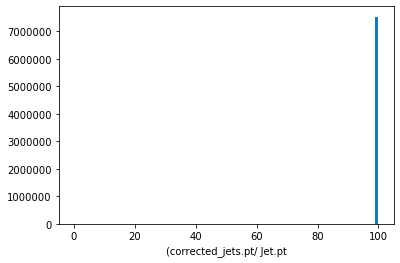

In [18]:
import matplotlib.pyplot as plt
import numpy as np

arr = ak.flatten((corrected_jets.pt_jec/events.Jet.pt))*100

plt.hist(arr, bins=np.linspace(0,100,100))
plt.xlabel("(corrected_jets.pt/ Jet.pt")
# plt.title()
plt.show()

In [54]:
corrected_jets.pt

<Array [[109, 39.9, 21.5, ... 21.2, 16.4]] type='133026 * var * float32'>

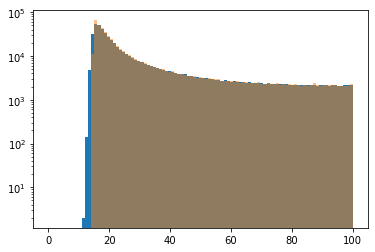

In [75]:
import matplotlib.pyplot as plt
import numpy as np

arr = ak.flatten((corrected_jets.pt-events.Jet.pt)/events.Jet.pt)*100

plt.hist(ak.flatten(corrected_jets.pt), bins=np.linspace(0,100,100), log=True,)
plt.hist(ak.flatten(events.Jet.pt), bins=np.linspace(0,100,100),log=True, alpha=0.5)
plt.show()

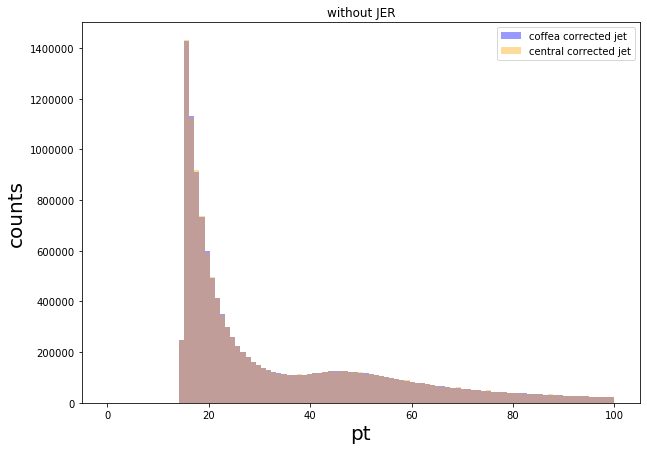

In [17]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

x = ak.flatten(corrected_jets.pt_jec)
y = ak.flatten(events.Jet.pt)


fig, ax = plt.subplots(figsize=[10,7])

ax.hist(x, bins=np.linspace(0,100,100), edgecolor='None', alpha = 0.4, color= 'blue', label="coffea corrected jet", )
ax.hist(y, bins=np.linspace(0,100,100), edgecolor='None', alpha = 0.4, color= 'orange', label="central corrected jet")


ax.legend()
ax.set_title("without JER")
ax.set_xlabel('pt', fontsize=20)
ax.set_ylabel('counts', fontsize=20)
plt.show()

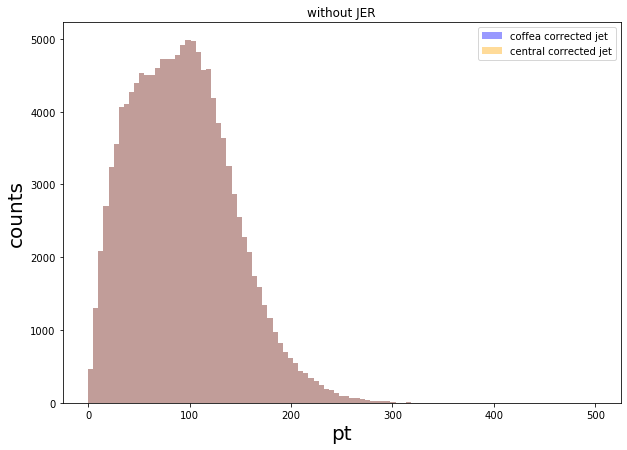

In [26]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

x = corrected_mets.pt_orig
y = events.MET.pt


fig, ax = plt.subplots(figsize=[10,7])

ax.hist(x, bins=np.linspace(0,500,100), edgecolor='None', alpha = 0.4, color= 'blue', label="coffea corrected jet", )
ax.hist(y, bins=np.linspace(0,500,100), edgecolor='None', alpha = 0.4, color= 'orange', label="central corrected jet")


ax.legend()
ax.set_title("without JER")
ax.set_xlabel('pt', fontsize=20)
ax.set_ylabel('counts', fontsize=20)
plt.show()

In [47]:
print(corrected_mets.phi)
print(corrected_mets.pt_orig)
print(events.MET.phi)


[-2.91, 1.88, -2.85, -2.06, 2.99, -0.284, ... -2.08, 1.2, -1.82, -0.45, 0.342, -2.83]
[78.3, 107, 132, 73.2, 45.7, 17.1, 17.3, ... 123, 57.5, 141, 63.8, 195, 57.7, 18]
[-2.96, 1.88, -2.84, -2.09, 3.07, -0.0222, ... 1.22, -1.77, -0.413, 0.103, 3.13]


In [202]:
len(x)- len(y)

10755

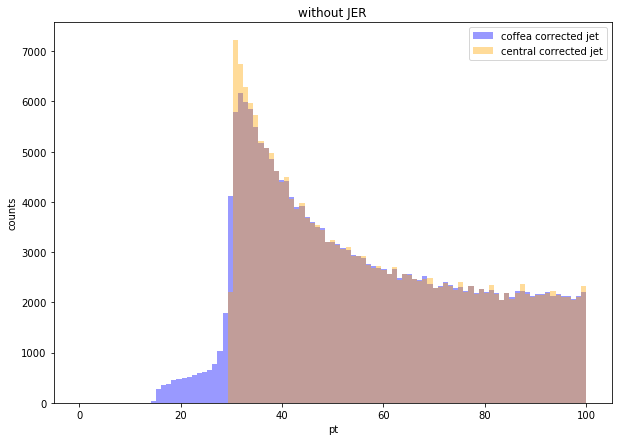

In [24]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
mask_corr = corrected_jets.pt>30
mask= events.Jet.pt>30

corrected_jets = corrected_jets[mask_corr]
regular_jets = events.Jet[mask]
x = ak.flatten(corrected_jets.pt_jec)
y = ak.flatten(regular_jets.pt)


fig, ax = plt.subplots(figsize=[10,7])

ax.hist(x, bins=np.linspace(0,100,100), edgecolor='None', alpha = 0.4, color= 'blue', label="coffea corrected jet",  )
ax.hist(y, bins=np.linspace(0,100,100), edgecolor='None', alpha = 0.4, color= 'orange', label="central corrected jet", )


ax.legend()
ax.set_title("without JER")
ax.set_xlabel('pt', fontsize=10)
ax.set_ylabel('counts', fontsize='medium')
plt.show()

In [23]:
jerUP =  corrected_jets['JER'].up.pt / events.Jet.pt_raw
jerDown = corrected_jets['JER'].down.pt / events.Jet.pt_raw

In [16]:
jerUP[0]

<Array [1.06, 0.999, 1.25, 1.11] type='4 * float32'>

In [18]:
jerDown

<Array [[1.05, 1.02, 1.2, ... 0.909, 1.03]] type='133026 * var * float32'>

In [21]:
ak.prod(jerUP, axis=1)

<Array [1.46, 0.994, 4.96, ... 4.81e-05, 0.927] type='133026 * float32'>

In [20]:
ak.prod(jerDown, axis=1)

<Array [1.57, 1.05, 2.62, ... 1.09, 0.2, 1.09] type='133026 * float32'>

In [24]:
for unc in jet_factory.uncertainties():
    print("Nominal normal Jets",j.pt)
    print("Nominal Corrected Jets",corrected_jets.pt)
#     print(unc)
    print(unc+"UP",corrected_jets[unc].up.pt)
    print(unc+"Down",corrected_jets[unc].down.pt, "\n")

Nominal normal Jets [[110, 40.4, 20.5, 15.3], [63.2, 28.9, ... 101, 53.8, 53.2, 36.8, 22.1, 21.8, 16.5]]
Nominal Corrected Jets [[110, 38.7, 21.3, 15.2], [61.9, 28.7, ... 150, 101, 56.3, 53, 35.3, 15.8, 22, 15.1]]
JERUP [[110, 38.3, 21.8, 14.5], [61.5, 28.6, ... 102, 58.7, 53.7, 35.1, 14.2, 22.3, 14.1]]
JERDown [[110, 39.2, 20.8, 16], [62.2, 28.7, ... 99.2, 54, 52.2, 35.6, 17.6, 21.7, 16.5]] 

Nominal normal Jets [[110, 40.4, 20.5, 15.3], [63.2, 28.9, ... 101, 53.8, 53.2, 36.8, 22.1, 21.8, 16.5]]
Nominal Corrected Jets [[110, 38.7, 21.3, 15.2], [61.9, 28.7, ... 150, 101, 56.3, 53, 35.3, 15.8, 22, 15.1]]
JES_jesUP [[111, 39.3, 22.6, 15.6], [62.7, 29.3, ... 102, 58.4, 53.9, 36, 17.2, 22.5, 15.7]]
JES_jesDown [[109, 38.1, 20, 14.9], [61.1, 28, ... 148, 99.3, 54.2, 52, 34.7, 14.3, 21.5, 14.6]] 



In [21]:
for unc in jet_factory.uncertainties():
    print("Nominal normal Jets",j.pt)
    print("Nominal Corrected Jets",corrected_jets.pt)
#     print(unc)
    print(unc+"UP",corrected_jets[unc].up.pt)
    print(unc+"Down",corrected_jets[unc].down.pt, "\n")

Nominal normal Jets [[110, 40.4, 20.5, 15.3], [63.2, 28.9, ... 101, 53.8, 53.2, 36.8, 22.1, 21.8, 16.5]]
Nominal Corrected Jets [[105, 37, 17.1, 11.7], [60.3, 26.2, ... 89.9, 53.6, 46.3, 37.5, 15.8, 25, 13.6]]
JERUP [[105, 36.4, 17, 10.6], [59.9, 25.9, ... 89.4, 55.5, 46.4, 37.4, 14.3, 25.5, 12.7]]
JERDown [[105, 37.6, 17.3, 12.9], [60.8, 26.5, ... 90.3, 51.6, 46.2, 37.6, 17.7, 24.6, 15]] 

Nominal normal Jets [[110, 40.4, 20.5, 15.3], [63.2, 28.9, ... 101, 53.8, 53.2, 36.8, 22.1, 21.8, 16.5]]
Nominal Corrected Jets [[105, 37, 17.1, 11.7], [60.3, 26.2, ... 89.9, 53.6, 46.3, 37.5, 15.8, 25, 13.6]]
JES_jesUP [[106, 37.6, 18.3, 12.1], [61.1, 26.9, ... 91.3, 55.6, 47.3, 38.1, 17.3, 25.5, 14.2]]
JES_jesDown [[104, 36.4, 16, 11.4], [59.5, 25.6, ... 88.4, 51.5, 45.4, 36.8, 14.4, 24.5, 13.1]] 



In [27]:
jerUP =  corrected_jets['JES_jes'].up
jerDown = corrected_jets['JES_jes'].down

In [28]:
jerUP.fields

['area',
 'btagCSVV2',
 'btagDeepB',
 'btagDeepCvB',
 'btagDeepCvL',
 'btagDeepFlavB',
 'btagDeepFlavCvB',
 'btagDeepFlavCvL',
 'btagDeepFlavQG',
 'chEmEF',
 'chFPV0EF',
 'chHEF',
 'eta',
 'hfsigmaEtaEta',
 'hfsigmaPhiPhi',
 'mass',
 'muEF',
 'muonSubtrFactor',
 'neEmEF',
 'neHEF',
 'phi',
 'pt',
 'puIdDisc',
 'qgl',
 'rawFactor',
 'bRegCorr',
 'bRegRes',
 'cRegCorr',
 'cRegRes',
 'electronIdx1',
 'electronIdx2',
 'hfadjacentEtaStripsSize',
 'hfcentralEtaStripSize',
 'jetId',
 'muonIdx1',
 'muonIdx2',
 'nElectrons',
 'nMuons',
 'puId',
 'nConstituents',
 'genJetIdx',
 'hadronFlavour',
 'partonFlavour',
 'cleanmask',
 'electronIdx1G',
 'electronIdx2G',
 'genJetIdxG',
 'muonIdx1G',
 'muonIdx2G',
 'muonIdxG',
 'electronIdxG',
 'pt_raw',
 'mass_raw',
 'pt_gen',
 'rho']

In [18]:
jet_factory.uncertainties()

['JER', 'JES_jes']

In [22]:
assembled = {"jec": {}, "junc": {}, "jer": {}, "jersf": {}}
for key in jec_inputs.keys():
    if "Uncertainty" in key:
        assembled["junc"][key] = jec_inputs[key]
    elif "SF" in key:
        assembled["jersf"][key] = jec_inputs[key]
    elif "Resolution" in key and "SF" not in key:
        assembled["jer"][key] = jec_inputs[key]
#     elif len(_levelre.findall(key)) > 0:
#         assembled["jec"][key] = corrections[key]

In [23]:
assembled

{'jec': {},
 'junc': {'Summer16_07Aug2017_V11_MC_Uncertainty_AK4PFchs': binned dims   : ['JetEta']
  eval vars     : ['JetPt']
  signature     : (JetEta,JetPt)},
 'jer': {'Summer16_25nsV1b_MC_PtResolution_AK4PFchs': binned dims: ['JetEta', 'Rho']
  eval vars  : ['JetPt']
  parameters : ['p0', 'p1', 'p2', 'p3']
  formula    : sqrt(p0*abs(p0)/(JetPt*JetPt)+p1*p1*pow(JetPt,p3)+p2*p2)
  signature  : (JetEta,Rho,JetPt)},
 'jersf': {'Summer16_25nsV1b_MC_SF_AK4PFchs': binned dims   : ['JetEta']
  eval vars     : []
  return format : ['central-up-down']
  formula       : None
  signature     : (JetEta)}}

In [26]:
original = ak.Array([[0, 1, 2], [], [3, 4], [5], [6, 7, 8, 9]])

counts = ak.num(original)

array = (ak.flatten(original))


# counts
# <Array [3, 0, 2, 1, 4] type='5 * int64'>

# array
# <Array [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] type='10 * int64'>

# ak.unflatten(array, counts)

In [27]:
array = np.ones(len(array))

In [28]:
array

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [29]:
ak.unflatten(array, counts)

<Array [[1, 1, 1], [], ... [1], [1, 1, 1, 1]] type='5 * var * float64'>

In [41]:
counts = ak.num(j)

In [42]:
counts

<Array [4, 3, 5, 3, 5, 5, ... 4, 5, 4, 2, 4, 8] type='133026 * int64'>

In [43]:
array = np.ones(len(ak.flatten(j)))

In [44]:
ak.unflatten(np.ones(len(ak.flatten(j))), counts)

<Array [[1, 1, 1, 1], ... 1, 1, 1, 1, 1, 1]] type='133026 * var * float64'>

In [37]:
len(array)

133026

In [49]:
events.genWeight[0]

4458.30615234375

In [ ]:
#junc_names = ['{0}_Uncertainty_AK4PFchs'.format(jec_tag)]
##levels = []
#if do_factorized_jec_unc:
#    for name in dir(evaluator):

#        #factorized sources
#        if '{0}_UncertaintySources_AK4PFchs'.format(jec_tag) in name:
#            junc_names.append(name)

#self.jesunc = JetCorrectionUncertainty(**{name: evaluator[name] for name in junc_names})
